In [1]:
import os
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from itertools import combinations
from scipy.stats import spearmanr
from statsmodels.stats.multitest import multipletests

os.makedirs("results", exist_ok=True)
models = {
    "logreg": pd.read_csv("results/logreg_predictions.csv", index_col=0),
    "nb": pd.read_csv("results/nb_predictions.csv", index_col=0),
    "svm": pd.read_csv("results/svm_predictions.csv", index_col=0)
}

samples = models["logreg"].index
assert samples.is_unique
for model in models.values():
    assert model.index.is_unique and set(model.index) == set(samples)
print(len(samples), "samples")

32 samples


In [2]:
def get_predictions(n):
    table = pd.DataFrame(index=samples)
    for name, data in models.items():
        cols = [c for c in data.columns if c.endswith(f"_{n}genes")]
        condition = [c for c in cols if "condition" in c.lower()]
        cluster = [c for c in cols if c not in condition]
        if len(condition) != 1 or len(cluster) != 1:
            raise ValueError(f"Check {name} columns for {n} genes: {cols}")
        table[f"{name}_class"] = data.loc[samples, condition[0]]
        table[f"{name}_cluster"] = data.loc[samples, cluster[0]]
    if table.isna().any().any():
        raise ValueError("Missing predictions in model output")
    return table

predictions = get_predictions(5000)
predictions.to_csv("results/q3_predictions_5000genes.csv")
predictions.head()

,logreg_class,logreg_cluster,nb_class,nb_cluster,svm_class,svm_cluster
refinebio_title,,,,,,
"Ground Control, 4 days old, Col-0 Rep1",0,0,1,1,0,0
"Ground Control, 4 days old, Col-0 Rep2",0,0,1,1,0,0
"Ground Control, 4 days old, Col-0 Rep3",0,0,0,1,0,0
"Ground Control, 4 days old, Col-0 Rep4",0,0,1,1,0,0
"Ground Control, 4 days old, WS Rep1",0,1,1,0,0,1


In [3]:
def count_votes(data):
    data = data.copy()
    class_cols = [f"{name}_class" for name in models]
    cluster_cols = [f"{name}_cluster" for name in models]
    for label in [0, 1]:
        data[f"class_{label}_votes"] = (data[class_cols] == label).sum(axis=1)
    data["class_agreement"] = data[["class_0_votes", "class_1_votes"]].max(axis=1)

    reference = data[cluster_cols[0]]
    aligned = pd.DataFrame(index=data.index)
    aligned["logreg"] = reference
    for name in ["nb", "svm"]:
        source = data[f"{name}_cluster"]
        mapping = pd.crosstab(source, reference).idxmax(axis=1)
        aligned[name] = source.map(mapping)
    for label in sorted(reference.unique()):
        data[f"aligned_cluster_{label}_votes"] = (aligned == label).sum(axis=1)
    data["cluster_agreement"] = aligned.apply(lambda row: row.value_counts().max(), axis=1)
    return data

counts = count_votes(predictions)
counts.head()

,logreg_class,logreg_cluster,nb_class,nb_cluster,svm_class,svm_cluster,class_0_votes,class_1_votes,class_agreement,aligned_cluster_0_votes,aligned_cluster_1_votes,cluster_agreement
refinebio_title,,,,,,,,,,,,
"Ground Control, 4 days old, Col-0 Rep1",0,0,1,1,0,0,2,1,2,3,0,3
"Ground Control, 4 days old, Col-0 Rep2",0,0,1,1,0,0,2,1,2,3,0,3
"Ground Control, 4 days old, Col-0 Rep3",0,0,0,1,0,0,3,0,3,3,0,3
"Ground Control, 4 days old, Col-0 Rep4",0,0,1,1,0,0,2,1,2,3,0,3
"Ground Control, 4 days old, WS Rep1",0,1,1,0,0,1,2,1,2,0,3,3


In [4]:
def cluster_stability(data):
    labels = [data[f"{name}_cluster"].to_numpy() for name in models]
    matrices = [x[:, None] == x[None, :] for x in labels]
    agreement = np.mean([a == b for a, b in combinations(matrices, 2)], axis=0)
    np.fill_diagonal(agreement, np.nan)
    return np.nanmean(agreement, axis=1)

counts["cluster_comembership_stability"] = cluster_stability(predictions)
counts.to_csv("results/q3_sample_agreement_5000genes.csv")
counts[["class_agreement", "cluster_agreement", "cluster_comembership_stability"]].head()

,class_agreement,cluster_agreement,cluster_comembership_stability
refinebio_title,,,
"Ground Control, 4 days old, Col-0 Rep1",2,3,1.000000
"Ground Control, 4 days old, Col-0 Rep2",2,3,1.000000
"Ground Control, 4 days old, Col-0 Rep3",3,3,1.000000
"Ground Control, 4 days old, Col-0 Rep4",2,3,1.000000
"Ground Control, 4 days old, WS Rep1",2,3,0.806452


In [5]:
rows = []
for n in [10, 100, 1000, 5000, 10000]:
    data = get_predictions(n)
    summary = count_votes(data)
    stability = cluster_stability(data)
    rho, p = spearmanr(summary["class_agreement"], stability)
    rows.append({"Genes": n, "Spearman_rho": rho, "p_value": p})

statistics = pd.DataFrame(rows)
valid = statistics["p_value"].notna()
statistics["FDR_BH"] = np.nan
if valid.any():
    statistics.loc[valid, "FDR_BH"] = multipletests(statistics.loc[valid, "p_value"], method="fdr_bh")[1]
statistics.to_csv("results/q3_stability_correlations.csv", index=False)
statistics

,Genes,Spearman_rho,p_value,FDR_BH
0,10,-0.129381,0.480348,0.515624
1,100,-0.119257,0.515624,0.515624
2,1000,-0.318142,0.075978,0.293523
3,5000,-0.225156,0.215351,0.358918
4,10000,-0.282354,0.117409,0.293523


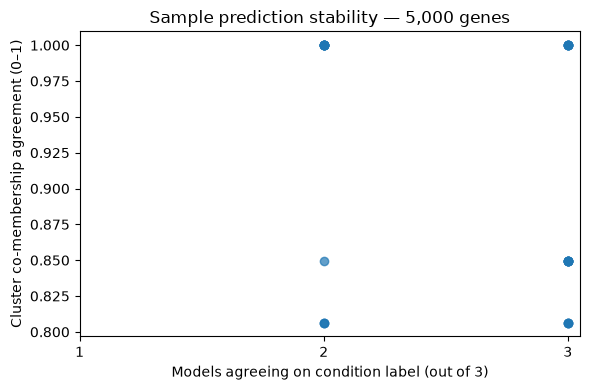

,Method,Genes,Target,AUC,Accuracy
6,Logistic Regression,5000,condition,1.000000,1.00000
7,Logistic Regression,5000,cluster_k2,1.000000,1.00000
16,Naive Bayes,5000,condition,0.593750,0.59375
17,Naive Bayes,5000,cluster_k3,0.946215,0.93750
26,SVM,5000,condition,1.000000,1.00000
27,SVM,5000,cluster_k2,0.996078,0.96875


In [6]:
auc_files = {
    "Logistic Regression": "results/logreg_auc_by_gene_count.csv",
    "Naive Bayes": "results/nb_auc_by_gene_count.csv",
    "SVM": "results/svm_auc_by_gene_count.csv"
}
auc_table = pd.concat([pd.read_csv(path) for path in auc_files.values()], ignore_index=True)
auc_table = auc_table.loc[auc_table["Genes"] == 5000].copy()
auc_table.to_csv("results/q3_model_auc_5000genes.csv", index=False)

plt.figure(figsize=(6, 4))
plt.scatter(counts["class_agreement"], counts["cluster_comembership_stability"], alpha=0.7)
plt.xlabel("Models agreeing on condition label (out of 3)")
plt.ylabel("Cluster co-membership agreement (0–1)")
plt.title("Sample prediction stability — 5,000 genes")
plt.xticks([1, 2, 3])
plt.tight_layout()
plt.savefig("results/q3_stability_5000genes.png", dpi=200)
plt.show()
auc_table